# Strategy Lab #1: Adaptive Volatility Targeting & Momentum

Welcome to Strategy Lab #1! This notebook builds a complete, institutional-grade quantitative strategy from the ground up. We are implementing an **Adaptive Volatility Targeting Strategy** applied to the S&P 500 (SPY).

This strategy is modeled on key empirical and quantitative research in adaptive leverage control and trend following, notably:
* **Proportional Volatility Feedback Control:** [Devanathan et al. (2026), *Single-Asset Adaptive Leveraged Volatility Control* (arXiv:2603.01298)](https://arxiv.org/abs/2603.01298)
* **Time-Series Momentum:** [Moskowitz, Ooi, & Pedersen (2012), *Time Series Momentum*](https://arxiv.org/abs/1201.0001)

The algorithm dynamically adjusts leverage to maintain a constant portfolio risk profile while using time-series momentum to dictate directional exposure. The notebook is structured into four core phases:

### Phase A & B: Core Logic (Momentum & Volatility Scaling)
* **Time-Series Momentum:** We measure the 1-year trailing return (skipping the most recent month to avoid short-term mean-reversion). The signal is scaled by the asset's long-term volatility.
* **Volatility Targeting:** The base target weight is inversely proportional to short-term realized volatility: $w_{target} = \frac{\sigma_{target}}{\sigma_{realized}}$.

### Phase C: Proportional Control & Friction
* **Feedback Loop:** A proportional control gain ($K_p$) actively nudges leverage based on tracking error between target volatility and actual realized volatility, correcting estimation lag through feedback loops.
* **Real-World Friction:** We penalize the strategy for transaction costs (10 bps turnover fee) and borrowing costs (5% annual interest on leverage > 1.0x).

### Phase D: Deadband Filter (Hysteresis)
* **Turnover Reduction:** In continuous volatility targeting, target weights fluctuate daily. To avoid micro-rebalances, we apply a 5% **Deadband Filter (Hysteresis)**. The algorithm only trades when the theoretical target weight deviates from current holdings by more than this threshold.


## Code (Setup & Installation):

In [ ]:
# Install yfinance if it isn't already installed in the environment
!pip install yfinance -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import yfinance as yf
from dataclasses import dataclass
from IPython.display import display
import warnings

warnings.filterwarnings('ignore')
# Set standard plotting style
plt.style.use('default')

## Strategy Engine & Backtest Execution
The cell below contains the full `AdaptiveVolBacktester` class and the execution logic.

**Key Configuration Parameters:**
* `target_vol = 0.10`: We target an annualized volatility of 10%.
* `Kp = 0.5`: The proportional control feedback gain.
* `w_max = 1.5`: Maximum allowed leverage is 1.5x (150% exposure).
* `turnover_threshold = 0.05`: The Phase D Hysteresis band (5%).


## Code (Core Algorithm & Plotting)

Fetching historical market data for S&P 500 ETF (SPY)...

================ BACKTEST PERFORMANCE SUMMARY ================


,Ann. Return,Ann. Volatility,Sharpe (rf=2%),Max Drawdown,Calmar Ratio
Strategy (Adaptive Vol),4.80%,10.00%,0.28,-23.12%,0.21
Benchmark (Buy & Hold),13.98%,17.17%,0.70,-33.72%,0.41


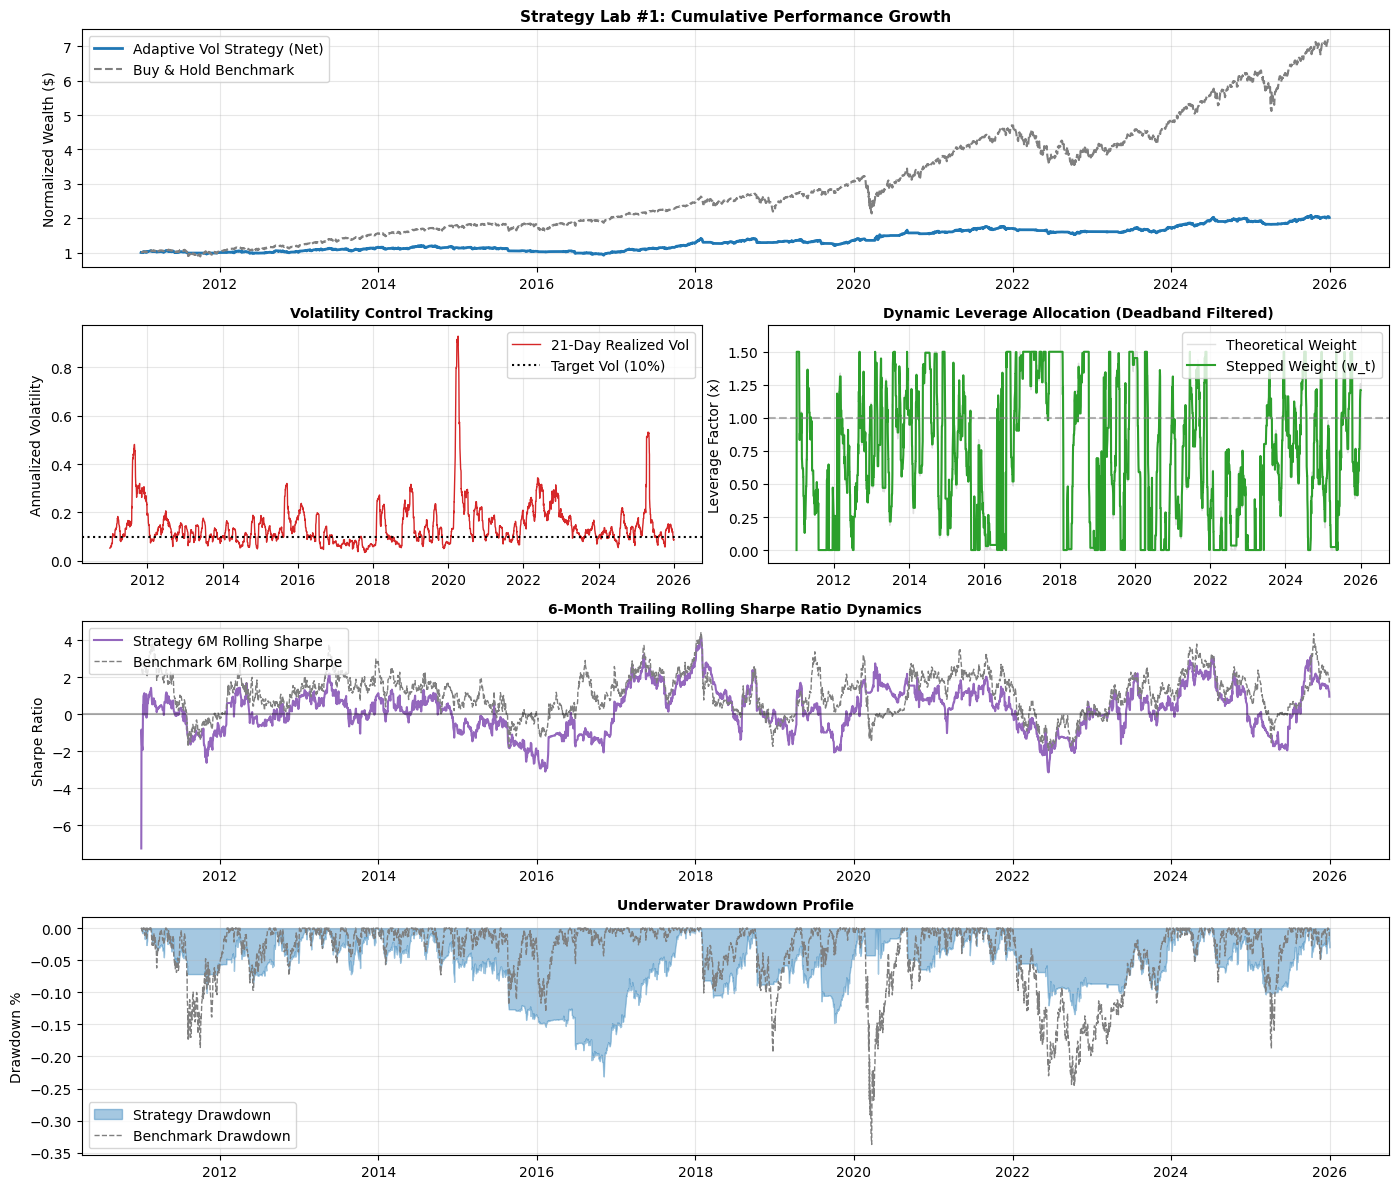

In [ ]:
# ----------------------------------------------------------------------
# 1. STRATEGY CONFIGURATION
# ----------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import yfinance as yf
from dataclasses import dataclass
from IPython.display import display
import warnings

warnings.filterwarnings('ignore')
plt.style.use('default')

@dataclass
class StrategyConfig:
    lookback: int = 252                 # Momentum lookback window (1 year)
    skip: int = 21                      # Reversal skip window (1 month)
    vol_window: int = 21                # Realized volatility window
    target_vol: float = 0.10            # 10% annualized target volatility
    Kp: float = 0.5                     # Proportional control feedback gain
    w_min: float = 0.0                  # Long-only constraint (0.0x)
    w_max: float = 1.5                  # Maximum leverage constraint (1.5x)
    transaction_cost_bps: float = 10.0  # 10 bps per trade turnover
    borrow_rate_annual: float = 0.05    # 5% annual interest on leverage > 1.0x
    turnover_threshold: float = 0.05    # Hysteresis: 5% deadband
    rolling_sharpe_window: int = 126    # 6-month window for rolling Sharpe calculation

# ----------------------------------------------------------------------
# 2. BACKTEST ENGINE
# ----------------------------------------------------------------------
class AdaptiveVolBacktester:
    def __init__(self, prices: pd.Series, config: StrategyConfig = StrategyConfig()):
        self.prices = prices.dropna()
        self.config = config
        self.results = None

    def compute_momentum_signal(self) -> pd.Series:
        """Phase A: Calculates volatility-scaled time-series momentum."""
        log_returns = np.log(self.prices).diff()
        eff_window = self.config.lookback - self.config.skip
        raw_signal = log_returns.rolling(eff_window).sum().shift(self.config.skip)
        long_vol = log_returns.rolling(self.config.lookback).std() * np.sqrt(252)
        long_vol = np.maximum(long_vol, 1e-6)
        return raw_signal / long_vol

    def compute_realized_vol(self, returns: pd.Series) -> pd.Series:
        """Phase B: Calculates short-term trailing realized volatility."""
        rvol = returns.rolling(self.config.vol_window).std() * np.sqrt(252)
        return np.maximum(rvol, 1e-4)

    def run_backtest(self) -> pd.DataFrame:
        """Executes full backtest logic (Phases A through D)."""
        returns = self.prices.pct_change().fillna(0.0)
        signal = self.compute_momentum_signal()
        rvol = self.compute_realized_vol(returns)

        # 1. Base Target Leverage
        w_ol = np.sign(signal) * (self.config.target_vol / rvol)

        # 2. Phase C: Proportional Feedback Correction
        tracking_error = self.config.target_vol - rvol
        direction = np.where(signal >= 0, 1.0, -1.0)
        w_correction = direction * self.config.Kp * (tracking_error / self.config.target_vol)

        # 3. Apply bounds
        raw_weights = w_ol + w_correction
        raw_weights = np.clip(raw_weights, self.config.w_min, self.config.w_max)

        # 4. Phase D: Hysteresis (Deadband Filter)
        raw_weights_arr = raw_weights.values
        buffered_weights = np.zeros_like(raw_weights_arr)
        current_w = 0.0

        for i in range(len(raw_weights_arr)):
            if abs(raw_weights_arr[i] - current_w) > self.config.turnover_threshold:
                current_w = raw_weights_arr[i]
            buffered_weights[i] = current_w

        weights = pd.Series(buffered_weights, index=raw_weights.index)

        # 5. Shift for Execution (t+1)
        executed_weights = weights.shift(1).fillna(0.0)

        # 6. Apply Friction (Turnover Costs & Borrowing)
        gross_returns = executed_weights * returns
        turnover = executed_weights.diff().abs().fillna(0.0)
        tc_pct = (self.config.transaction_cost_bps / 10000.0) * turnover

        leveraged_borrow = np.maximum(0.0, executed_weights - 1.0)
        daily_borrow_cost = leveraged_borrow * (self.config.borrow_rate_annual / 252.0)

        net_returns = gross_returns - tc_pct - daily_borrow_cost

        # 7. Compute Rolling Sharpe Ratios
        rf_daily = 0.02 / 252.0
        w = self.config.rolling_sharpe_window

        strat_excess = net_returns - rf_daily
        bench_excess = returns - rf_daily

        roll_sharpe_strat = (strat_excess.rolling(w).mean() * 252) / (net_returns.rolling(w).std() * np.sqrt(252))
        roll_sharpe_bench = (bench_excess.rolling(w).mean() * 252) / (returns.rolling(w).std() * np.sqrt(252))

        # Compile DataFrame
        df = pd.DataFrame({
            'Price': self.prices,
            'Asset_Returns': returns,
            'Signal': signal,
            'Realized_Vol': rvol,
            'Theoretical_Weight': raw_weights,
            'Executed_Weight': executed_weights,
            'Turnover': turnover,
            'Gross_Returns': gross_returns,
            'Net_Returns': net_returns,
            'Rolling_Sharpe_Strat': roll_sharpe_strat,
            'Rolling_Sharpe_Bench': roll_sharpe_bench
        }).dropna()

        df['Equity_Strategy'] = (1 + df['Net_Returns']).cumprod()
        df['Equity_Benchmark'] = (1 + df['Asset_Returns']).cumprod()

        self.results = df
        return df

    def compute_metrics(self) -> pd.DataFrame:
        """Calculates risk-adjusted performance statistics."""
        df = self.results
        ann_factor = 252

        def metrics_for_series(ser):
            c_ret = (1 + ser).cumprod()
            tot_ret = c_ret.iloc[-1] - 1
            ann_ret = (1 + tot_ret) ** (ann_factor / len(ser)) - 1
            ann_vol = ser.std() * np.sqrt(ann_factor)
            sharpe = (ann_ret - 0.02) / ann_vol if ann_vol > 0 else 0.0
            max_dd = ((c_ret - c_ret.cummax()) / c_ret.cummax()).min()
            calmar = ann_ret / abs(max_dd) if max_dd != 0 else 0.0
            return [ann_ret, ann_vol, sharpe, max_dd, calmar]

        strat_m = metrics_for_series(df['Net_Returns'])
        bench_m = metrics_for_series(df['Asset_Returns'])

        metrics_df = pd.DataFrame(
            [strat_m, bench_m],
            columns=['Ann. Return', 'Ann. Volatility', 'Sharpe (rf=2%)', 'Max Drawdown', 'Calmar Ratio'],
            index=['Strategy (Adaptive Vol)', 'Benchmark (Buy & Hold)']
        )
        return metrics_df.style.format("{:.2%}".format, subset=['Ann. Return', 'Ann. Volatility', 'Max Drawdown'])\
                               .format("{:.2f}", subset=['Sharpe (rf=2%)', 'Calmar Ratio'])

    def plot_dashboard(self):
        """Generates comprehensive visual dashboard including Rolling Sharpe."""
        df = self.results
        fig = plt.figure(figsize=(14, 12))
        gs = gridspec.GridSpec(4, 2, figure=fig)

        c_strat, c_bench, c_vol, c_weight, c_sharpe = '#1f77b4', '#7f7f7f', '#d62728', '#2ca02c', '#9467bd'

        # 1. Cumulative Performance
        ax1 = fig.add_subplot(gs[0, :])
        ax1.plot(df.index, df['Equity_Strategy'], label='Adaptive Vol Strategy (Net)', color=c_strat, lw=2)
        ax1.plot(df.index, df['Equity_Benchmark'], label='Buy & Hold Benchmark', color=c_bench, lw=1.5, linestyle='--')
        ax1.set_title("Strategy Lab #1: Cumulative Performance Growth", fontsize=11, fontweight='bold')
        ax1.set_ylabel("Normalized Wealth ($)")
        ax1.grid(True, alpha=0.3)
        ax1.legend(loc='upper left')

        # 2. Realized Volatility vs Target
        ax2 = fig.add_subplot(gs[1, 0])
        ax2.plot(df.index, df['Realized_Vol'], label='21-Day Realized Vol', color=c_vol, lw=1)
        ax2.axhline(self.config.target_vol, color='black', linestyle=':', label='Target Vol (10%)')
        ax2.set_title("Volatility Control Tracking", fontsize=10, fontweight='bold')
        ax2.set_ylabel("Annualized Volatility")
        ax2.grid(True, alpha=0.3)
        ax2.legend(loc='upper right')

        # 3. Dynamic Leverage & Hysteresis Effect
        ax3 = fig.add_subplot(gs[1, 1])
        ax3.plot(df.index, df['Theoretical_Weight'], label='Theoretical Weight', color='lightgray', lw=1, alpha=0.7)
        ax3.plot(df.index, df['Executed_Weight'], label='Stepped Weight (w_t)', color=c_weight, lw=1.5)
        ax3.axhline(1.0, color='gray', linestyle='--', alpha=0.6)
        ax3.set_title("Dynamic Leverage Allocation (Deadband Filtered)", fontsize=10, fontweight='bold')
        ax3.set_ylabel("Leverage Factor (x)")
        ax3.set_ylim(-0.1, self.config.w_max + 0.2)
        ax3.grid(True, alpha=0.3)
        ax3.legend(loc='upper right')

        # 4. Rolling Sharpe Ratio Plot (6-Month Trailing)
        ax4 = fig.add_subplot(gs[2, :])
        ax4.plot(df.index, df['Rolling_Sharpe_Strat'], label='Strategy 6M Rolling Sharpe', color=c_sharpe, lw=1.5)
        ax4.plot(df.index, df['Rolling_Sharpe_Bench'], label='Benchmark 6M Rolling Sharpe', color=c_bench, lw=1, linestyle='--')
        ax4.axhline(0.0, color='black', linestyle='-', alpha=0.3)
        ax4.set_title("6-Month Trailing Rolling Sharpe Ratio Dynamics", fontsize=10, fontweight='bold')
        ax4.set_ylabel("Sharpe Ratio")
        ax4.grid(True, alpha=0.3)
        ax4.legend(loc='upper left')

        # 5. Underwater Plot (Drawdown)
        ax5 = fig.add_subplot(gs[3, :])
        dd_strat = (df['Equity_Strategy'] - df['Equity_Strategy'].cummax()) / df['Equity_Strategy'].cummax()
        dd_bench = (df['Equity_Benchmark'] - df['Equity_Benchmark'].cummax()) / df['Equity_Benchmark'].cummax()

        ax5.fill_between(df.index, dd_strat, 0, color=c_strat, alpha=0.4, label='Strategy Drawdown')
        ax5.plot(df.index, dd_bench, color=c_bench, lw=1, linestyle='--', label='Benchmark Drawdown')
        ax5.set_title("Underwater Drawdown Profile", fontsize=10, fontweight='bold')
        ax5.set_ylabel("Drawdown %")
        ax5.grid(True, alpha=0.3)
        ax5.legend(loc='lower left')

        plt.tight_layout()
        plt.show()

# ----------------------------------------------------------------------
# 3. EXECUTION SCRIPT
# ----------------------------------------------------------------------
if __name__ == "__main__":
    print("Fetching historical market data for S&P 500 ETF (SPY)...")
    try:
        data = yf.download("SPY", start="2010-01-01", end="2026-01-01", progress=False)['Close']
        prices = data.squeeze() if isinstance(data, pd.DataFrame) else data
    except Exception as e:
        print(f"yfinance fetch failed: {e}")
        prices = pd.Series(dtype=float)

    if not prices.empty:
        cfg = StrategyConfig(target_vol=0.10, Kp=0.5, turnover_threshold=0.05, rolling_sharpe_window=126)
        engine = AdaptiveVolBacktester(prices, cfg)
        results = engine.run_backtest()

        print("\n================ BACKTEST PERFORMANCE SUMMARY ================")
        display(engine.compute_metrics())

        # Plot full dashboard including Rolling Sharpe
        engine.plot_dashboard()

